# Feature engineering

Création de variables plus informatives à partir des 96 colonnes brutes, et les intégrer dans un `Pipeline` scikit-learn sans fuite de données.

Les variables découlent des constats de l'analyse exploratoire (`02_eda.ipynb`) :

| Constat de l'EDA | Variable créée |
| --- | --- |
| Les écarts entre équipes sont les plus corrélés à la victoire | `players_alive_diff`, `health_diff`, `armor_diff`, `money_diff`, … |
| Les ~70 colonnes d'armes sont presque toujours à 0 | Regroupement par catégorie : fusils, AWP, autres snipers, SMG, armes lourdes, pistolets |
| L'effet du temps restant s'inverse quand la bombe est posée | `time_left_no_bomb` et `time_left_bomb` |
| La carte est une variable texte | Encodage one-hot dans le pipeline |

Le test reste de côté : les configurations sont comparées par **validation croisée groupée** (`GroupKFold`, 5 plis) sur le train : chaque match est entièrement dans un seul pli.

## 0. Imports et données

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict

from src.config import ROOT_DIR, SEED, TARGET
from src.rounds import load_processed
from src.features import BASE_COLUMNS, FeatureBuilder, build_pipeline, build_raw_pipeline
from src.leakage import all_features
from src.evaluation import grouped_cv, summarize_cv
from src.viz import COLOR_CT, COLOR_T, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()
df = load_processed()
train = df[df["split"] == "train"].reset_index(drop=True)
print(f"Train : {len(train):,} lignes, {train['match_id'].nunique()} matchs (le test n'est pas utilisé ici)")

Train : 97,431 lignes, 560 matchs (le test n'est pas utilisé ici)


## 1. Les variables créées

La classe `FeatureBuilder` (dans `src/features.py`) calcule toutes les variables ligne par ligne. Elle n'apprend rien sur les données : elle ne peut donc pas créer de fuite.

In [2]:
features = FeatureBuilder().transform(train)
groups = {
    "Base (gardées telles quelles)": [c for c in features.columns if c in
        ["time_left", "ct_score", "t_score", "ct_health", "t_health", "ct_armor", "t_armor",
         "ct_money", "t_money", "ct_helmets", "t_helmets", "ct_defuse_kits",
         "ct_players_alive", "t_players_alive", "bomb_planted"]],
    "Équipement par catégorie": [c for c in features.columns if any(
        c.endswith(s) for s in ["_rifle", "_awp", "_other_sniper", "_smg", "_heavy", "_pistol",
                                "_grenades", "_primary"]) and not c.endswith("_diff")],
    "Écarts T - CT": [c for c in features.columns if c.endswith("_diff") and c != "score_diff"],
    "Moyennes par joueur vivant": [c for c in features.columns if "per_player" in c],
    "Temps et bombe": ["time_left_no_bomb", "time_left_bomb"],
    "Contexte du match": ["round_number", "score_diff"],
    "Carte (one-hot ensuite)": ["map"],
}
summary = pd.DataFrame([{"groupe": g, "nombre": len(c), "variables": ", ".join(c)} for g, c in groups.items()])
n_raw = len(all_features(train)) + 1  # + la carte
print(f"{n_raw} colonnes brutes -> {features.shape[1]} variables créées")
summary.style.hide(axis="index")

96 colonnes brutes -> 49 variables créées


groupe,nombre,variables
Base (gardées telles quelles),15,"time_left, ct_score, t_score, ct_health, t_health, ct_armor, t_armor, ct_money, t_money, ct_helmets, t_helmets, ct_defuse_kits, ct_players_alive, t_players_alive, bomb_planted"
Équipement par catégorie,16,"ct_rifle, ct_awp, ct_other_sniper, ct_smg, ct_heavy, ct_pistol, ct_grenades, ct_primary, t_rifle, t_awp, t_other_sniper, t_smg, t_heavy, t_pistol, t_grenades, t_primary"
Écarts T - CT,9,"players_alive_diff, health_diff, armor_diff, money_diff, helmets_diff, grenades_diff, primary_diff, rifle_diff, awp_diff"
Moyennes par joueur vivant,4,"ct_health_per_player, ct_armor_per_player, t_health_per_player, t_armor_per_player"
Temps et bombe,2,"time_left_no_bomb, time_left_bomb"
Contexte du match,2,"round_number, score_diff"
Carte (one-hot ensuite),1,map


### Vérification sur une ligne

On contrôle le calcul sur une photo prise au hasard : chaque écart doit être égal à la valeur T moins la valeur CT.

In [3]:
row = train.sample(1, random_state=SEED).index[0]
check = pd.DataFrame({
    "T": [train.loc[row, "t_players_alive"], train.loc[row, "t_health"], train.loc[row, "t_money"]],
    "CT": [train.loc[row, "ct_players_alive"], train.loc[row, "ct_health"], train.loc[row, "ct_money"]],
    "écart calculé": [features.loc[row, "players_alive_diff"], features.loc[row, "health_diff"],
                      features.loc[row, "money_diff"]],
}, index=["joueurs vivants", "santé", "argent"])
check

,T,CT,écart calculé
joueurs vivants,5.0,5.0,0.0
santé,500.0,494.0,6.0
argent,1650.0,2200.0,-550.0


## 2. Les variables créées améliorent-elles les modèles ?

On compare trois familles de modèles, chacune avec les **variables brutes** puis avec les **variables créées** :

| Modèle | Pourquoi |
| --- | --- |
| Régression logistique | modèle linéaire simple, sensible à la qualité des variables |
| Random Forest régularisé (`min_samples_leaf=20`) | même famille que la première version, avec moins de sur-apprentissage |
| Gradient Boosting (`HistGradientBoosting`) | souvent le plus performant sur ce type de données |

Les hyperparamètres ne sont pas optimisés : seule l'influence des variables est comparée ici.

In [4]:
models = {
    "Régression logistique": (lambda: LogisticRegression(max_iter=2000), True),
    "Random Forest": (lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                                     n_jobs=-1, random_state=SEED), False),
    "Gradient Boosting": (lambda: HistGradientBoostingClassifier(random_state=SEED), False),
}
cv_results = {}
for name, (make_model, scale) in models.items():
    cv_results[(name, "brutes")] = grouped_cv(build_raw_pipeline(make_model(), scale=scale), train)
    cv_results[(name, "créées")] = grouped_cv(build_pipeline(make_model(), scale=scale), train)
    print(f"{name} : terminé")

table = summarize_cv({f"{m} | {v}": r for (m, v), r in cv_results.items()})
table[["modèle", "variables"]] = table["configuration"].str.split(" | ", regex=False, expand=True)
table = table[["modèle", "variables", "accuracy", "accuracy_std", "roc_auc", "log_loss", "brier", "seconds"]]

reports = ROOT_DIR / "reports"
reports.mkdir(exist_ok=True)
table.to_csv(reports / "cv_etape4_variables.csv", index=False)
table.style.format({"accuracy": "{:.2%}", "accuracy_std": "± {:.2%}", "roc_auc": "{:.4f}",
                    "log_loss": "{:.4f}", "brier": "{:.4f}", "seconds": "{:.0f} s"}).hide(axis="index")

Régression logistique : terminé
Random Forest : terminé
Gradient Boosting : terminé


modèle,variables,accuracy,accuracy_std,roc_auc,log_loss,brier,seconds
Régression logistique,brutes,70.13%,± 0.68%,0.7938,0.5352,0.1832,16 s
Régression logistique,créées,70.25%,± 0.51%,0.7960,0.5303,0.1821,19 s
Random Forest,brutes,70.53%,± 0.54%,0.8028,0.5224,0.1784,105 s
Random Forest,créées,70.73%,± 0.65%,0.8053,0.5155,0.1767,110 s
Gradient Boosting,brutes,70.78%,± 0.67%,0.8038,0.5177,0.1777,54 s
Gradient Boosting,créées,70.92%,± 0.64%,0.8051,0.5159,0.1771,38 s


Accuracy et ROC-AUC : plus haut = mieux. Log loss et Brier : plus bas = mieux ; ces deux métriques mesurent la qualité des probabilités, qui sont la vraie sortie du modèle. Une différence plus petite que `accuracy_std` (écart-type entre les plis) n'est pas significative.

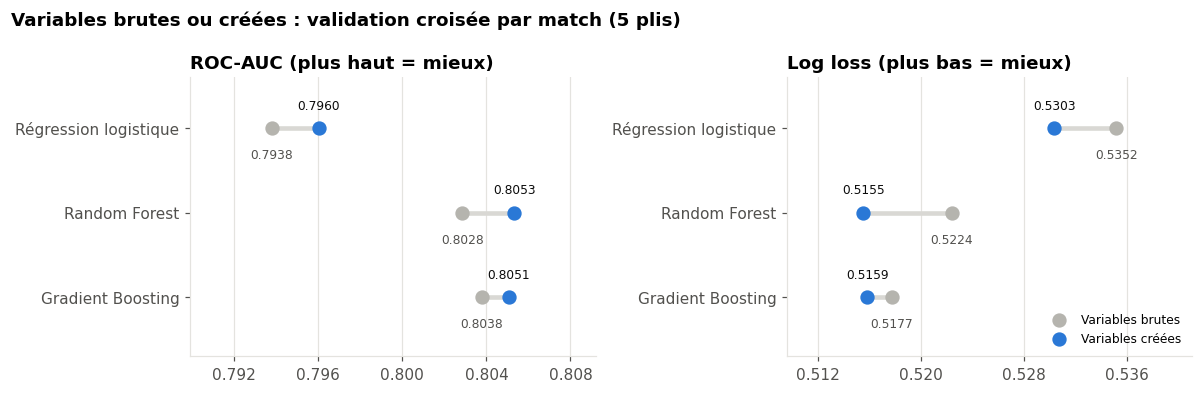

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, title in [(axes[0], "roc_auc", "ROC-AUC (plus haut = mieux)"),
                          (axes[1], "log_loss", "Log loss (plus bas = mieux)")]:
    pivot = table.pivot(index="modèle", columns="variables", values=metric).loc[list(models)[::-1]]
    for y, (name, r) in enumerate(pivot.iterrows()):
        ax.plot([r["brutes"], r["créées"]], [y, y], color="#d9d8d4", linewidth=3, zorder=1)
        ax.scatter(r["brutes"], y, s=70, color="#b5b4ae", zorder=2, label="Variables brutes" if y == 0 else None)
        ax.scatter(r["créées"], y, s=70, color=COLOR_CT, zorder=3, label="Variables créées" if y == 0 else None)
        ax.text(r["créées"], y + 0.22, f"{r['créées']:.4f}", ha="center", fontsize=8, color=COLOR_TEXT)
        ax.text(r["brutes"], y - 0.36, f"{r['brutes']:.4f}", ha="center", fontsize=8, color=COLOR_TEXT_MUTED)
    lo, hi = pivot.min().min(), pivot.max().max()
    pad = (hi - lo) * 0.25 + 0.001
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(-0.7, len(pivot) - 0.4)
    ax.set_yticks(range(len(pivot)), pivot.index)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[1].legend(loc="lower right", fontsize=8)
fig.suptitle("Variables brutes ou créées : validation croisée par match (5 plis)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "08_variables_brutes_vs_creees")
plt.show()

Chaque ligne relie le score avec les variables brutes (gris) au score avec les variables créées (bleu). Les écarts sont de l'ordre du millième : l'axe est volontairement zoomé pour les rendre visibles.

## 3. Où le modèle se trompe-t-il ?

Les scores plafonnent autour de 70 % quel que soit le modèle. Pour comprendre pourquoi, on regarde l'accuracy selon la situation de jeu, avec les prédictions de validation croisée du Gradient Boosting (chaque ligne est prédite par un modèle qui n'a jamais vu son match).

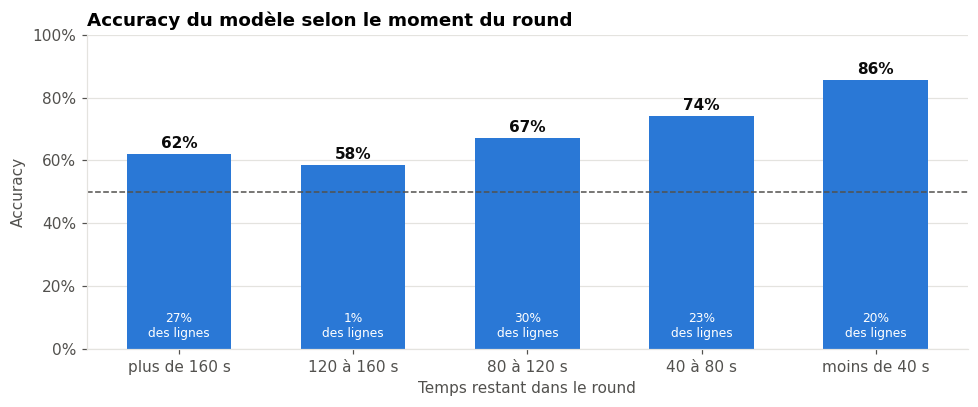

In [6]:
best_pipe = build_pipeline(HistGradientBoostingClassifier(random_state=SEED))
proba = cross_val_predict(best_pipe, train, train[TARGET], groups=train["match_id"],
                          cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
err = train[["time_left", "bomb_planted", "ct_players_alive", "t_players_alive", TARGET]].copy()
err["correct"] = (proba >= 0.5).astype(int) == err[TARGET]
err["phase"] = pd.cut(err["time_left"], [-1, 40, 80, 120, 160, 176],
                      labels=["moins de 40 s", "40 à 80 s", "80 à 120 s", "120 à 160 s", "plus de 160 s"])
err["écart de joueurs"] = (err["t_players_alive"] - err["ct_players_alive"]).clip(-2, 2).astype(int)

by_phase = err.groupby("phase", observed=True)["correct"].agg(accuracy="mean", lignes="size")
by_phase["part des lignes"] = by_phase["lignes"] / by_phase["lignes"].sum()
by_phase = by_phase.iloc[::-1]  # du début à la fin du round

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(by_phase.index.astype(str), by_phase["accuracy"], color=COLOR_CT, width=0.6)
for bar, acc, share in zip(bars, by_phase["accuracy"], by_phase["part des lignes"]):
    ax.text(bar.get_x() + bar.get_width() / 2, acc + 0.01, f"{acc:.0%}", ha="center",
            va="bottom", fontsize=10, fontweight="bold", color=COLOR_TEXT)
    ax.text(bar.get_x() + bar.get_width() / 2, 0.03, f"{share:.0%}\ndes lignes", ha="center",
            va="bottom", fontsize=8, color="white")
ax.axhline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Temps restant dans le round")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy du modèle selon le moment du round")
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "09_accuracy_par_phase")
plt.show()

In [7]:
pd.concat({
    "Bombe posée": err.groupby(err["bomb_planted"].astype(bool))["correct"].mean()
                      .rename(index={False: "non", True: "oui"}),
    "Écart de joueurs (T - CT)": err.groupby("écart de joueurs")["correct"].mean(),
}).to_frame("accuracy").style.format("{:.1%}")

## 4. Importance des variables

Importance par diminution moyenne d'impureté (Random Forest entraîné sur tout le train). Cette mesure favorise les variables continues : c'est une première indication, à confirmer avec SHAP.

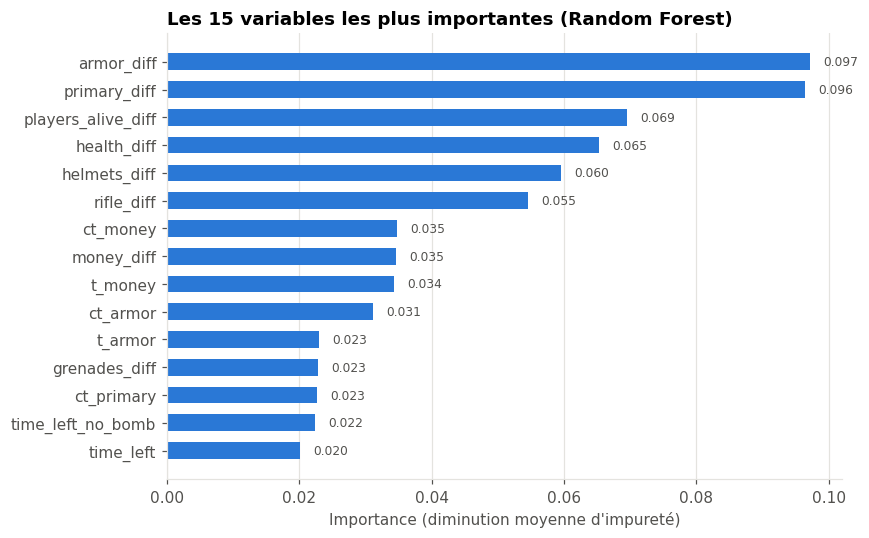

Variables créées dans le top 15 : 10 sur 15


In [8]:
rf_pipe = build_pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                                 n_jobs=-1, random_state=SEED))
rf_pipe.fit(train, train[TARGET])
names = rf_pipe.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
top = importance.sort_values().tail(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=COLOR_CT, height=0.6)
for y, v in enumerate(top.values):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8, color=COLOR_TEXT_MUTED)
ax.set_xlabel("Importance (diminution moyenne d'impureté)")
ax.set_title("Les 15 variables les plus importantes (Random Forest)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "10_importance_variables")
plt.show()
created = set(features.columns) - set(BASE_COLUMNS) - {"bomb_planted", "map"}
print(f"Variables créées dans le top 15 : {sum(n in created for n in top.index)} sur 15")

## 5. Résumé des résultats

In [9]:
t = table.set_index(["modèle", "variables"])
print("=== Résumé ===")
print(f"Variables : {n_raw} colonnes brutes -> {features.shape[1]} variables créées")
for m in models:
    b, c = t.loc[(m, "brutes")], t.loc[(m, "créées")]
    print(f"{m:<22}: accuracy {b['accuracy']:.2%} -> {c['accuracy']:.2%} | "
          f"AUC {b['roc_auc']:.4f} -> {c['roc_auc']:.4f} | log loss {b['log_loss']:.4f} -> {c['log_loss']:.4f}")
print("Accuracy par phase (Gradient Boosting, variables créées) :")
for phase, r in by_phase.iterrows():
    print(f"   {phase:<14}: {r['accuracy']:.1%} ({r['part des lignes']:.0%} des lignes)")

=== Résumé ===
Variables : 96 colonnes brutes -> 49 variables créées
Régression logistique : accuracy 70.13% -> 70.25% | AUC 0.7938 -> 0.7960 | log loss 0.5352 -> 0.5303
Random Forest         : accuracy 70.53% -> 70.73% | AUC 0.8028 -> 0.8053 | log loss 0.5224 -> 0.5155
Gradient Boosting     : accuracy 70.78% -> 70.92% | AUC 0.8038 -> 0.8051 | log loss 0.5177 -> 0.5159
Accuracy par phase (Gradient Boosting, variables créées) :
   plus de 160 s : 62.0% (27% des lignes)
   120 à 160 s   : 58.4% (1% des lignes)
   80 à 120 s    : 67.0% (30% des lignes)
   40 à 80 s     : 74.1% (23% des lignes)
   moins de 40 s : 85.5% (20% des lignes)


## Conclusion

**Variables :** les 96 colonnes brutes sont remplacées par 49 variables (écarts entre équipes, équipement par catégorie, temps séparé selon la bombe, contexte du match), plus l'encodage one-hot de la carte. 10 des 15 variables les plus importantes du Random Forest sont des variables créées, avec en tête `armor_diff`, `primary_diff` et `players_alive_diff`.

**Effet sur les modèles (validation croisée par match, 5 plis) :**

| Modèle | Accuracy (brutes → créées) | ROC-AUC | Log loss |
| --- | --- | --- | --- |
| Régression logistique | 70,13 % → 70,25 % | 0,7938 → 0,7960 | 0,5352 → 0,5303 |
| Random Forest | 70,53 % → 70,73 % | 0,8028 → 0,8053 | 0,5224 → 0,5155 |
| Gradient Boosting | 70,78 % → 70,92 % | 0,8038 → 0,8051 | 0,5177 → 0,5159 |

Les variables créées améliorent les trois modèles sur toutes les métriques, mais les gains sont faibles : sur l'accuracy, ils restent plus petits que la variation entre les plis (environ ± 0,6 point). L'amélioration la plus nette concerne la qualité des probabilités (log loss du Random Forest : 0,5224 → 0,5155).

**Pourquoi un plafond autour de 71 % ?** La limite vient de l'information disponible, pas des variables. Au début d'un round (plus de 160 s restantes, 27 % des lignes), les deux équipes sont à 5 contre 5 et le modèle n'atteint que 62,0 % : l'issue est encore très incertaine. En fin de round (moins de 40 s), il atteint 85,5 %, et 91,1 % quand la bombe est posée. L'accuracy globale est donc une moyenne entre des situations quasi imprévisibles et des situations presque jouées.

**Décision :** les variables créées sont conservées. Elles donnent un modèle deux fois plus compact, plus facile à interpréter, avec des probabilités légèrement meilleures. Le Gradient Boosting (70,92 %, ROC-AUC 0,8051) et le Random Forest (70,73 %, ROC-AUC 0,8053) sont les meilleurs candidats.